# Description:

- This dataset contains top rated movies from IMDb website, gathered based on different genres and are also in different languages. Movies from the early 1930s to current year titles are collected, cleaned and arranged in this dataset.

#### Columns Description
 - 'Movie_Title' : Consist of 5000+ Movie Titles (5000+ Unique Values)
 - 'Year' : Ranging from 1920s to 2022 (99 Unique Values)
 - 'Director' : Names the Director (2000+ Unique Values)
 - 'Actors' : Names the Actors (5000+ Unique & Multiple Values)
 - 'Rating' : Titles rated for 10 by 25k+ Voters (74+ Unique Values)
 - 'main_genre' : Main Genre of the Title (13+ Unique Values)
 - 'side_genre' : Side / Multiple Genre of the Movie (144+ Unique & Multiple Values)
 - 'Runtime(Mins)' : Total duration of the movie in Minutes (156+ Unique Values)
 - 'Censor' : Censorship of the Movie (25+ Unique Values)
 - 'Total_Gross' : Total Box-Office Collection of the Movie (3500+ Unique Values)

### Dataset url : https://www.kaggle.com/datasets/rakkesharv/imdb-5000-movies-multiple-genres-dataset

# Importing the libraries

In [106]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import plotly.express as px
import cufflinks as cf

# Step 1: Descriptive Statistics

In [107]:
df = pd.read_csv(r'D:\IMDb_All_Genres_etf_clean1.csv')

In [108]:
df.head()

,Movie_Title,Year,Director,Actors,Rating,Runtime(Mins),Censor,Total_Gross,main_genre,side_genre
0,Kantara,2022,Rishab Shetty,"Rishab Shetty, Sapthami Gowda, Kishore Kumar G...",9.3,148,UA,Gross Unkown,Action,"Adventure, Drama"
1,The Dark Knight,2008,Christopher Nolan,"Christian Bale, Heath Ledger, Aaron Eckhart, M...",9.0,152,UA,$534.86M,Action,"Crime, Drama"
2,The Lord of the Rings: The Return of the King,2003,Peter Jackson,"Elijah Wood, Viggo Mortensen, Ian McKellen, Or...",9.0,201,U,$377.85M,Action,"Adventure, Drama"
3,Inception,2010,Christopher Nolan,"Leonardo DiCaprio, Joseph Gordon-Levitt, Ellio...",8.8,148,UA,$292.58M,Action,"Adventure, Sci-Fi"
4,The Lord of the Rings: The Two Towers,2002,Peter Jackson,"Elijah Wood, Ian McKellen, Viggo Mortensen, Or...",8.8,179,UA,$342.55M,Action,"Adventure, Drama"


In [109]:
df.dtypes

Movie_Title       object
Year               int64
Director          object
Actors            object
Rating           float64
Runtime(Mins)      int64
Censor            object
Total_Gross       object
main_genre        object
side_genre        object
dtype: object

In [110]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5562 entries, 0 to 5561
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Movie_Title    5562 non-null   object 
 1   Year           5562 non-null   int64  
 2   Director       5562 non-null   object 
 3   Actors         5562 non-null   object 
 4   Rating         5562 non-null   float64
 5   Runtime(Mins)  5562 non-null   int64  
 6   Censor         5562 non-null   object 
 7   Total_Gross    5562 non-null   object 
 8   main_genre     5562 non-null   object 
 9   side_genre     5562 non-null   object 
dtypes: float64(1), int64(2), object(7)
memory usage: 434.7+ KB


In [111]:
df.duplicated().sum()

8

In [112]:
df.drop_duplicates(inplace=True)

In [113]:
df.isnull().sum()

Movie_Title      0
Year             0
Director         0
Actors           0
Rating           0
Runtime(Mins)    0
Censor           0
Total_Gross      0
main_genre       0
side_genre       0
dtype: int64

In [114]:
df.shape

(5554, 10)

In [115]:
for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")

Movie_Title: 5453 unique values
Year: 99 unique values
Director: 2320 unique values
Actors: 5511 unique values
Rating: 74 unique values
Runtime(Mins): 156 unique values
Censor: 25 unique values
Total_Gross: 3501 unique values
main_genre: 13 unique values
side_genre: 144 unique values


In [116]:
def check_data(df):
    print("1. Missing Values Analysis:")
    print("-" * 50)

    print("NaN Values:")
    print(df.isna().sum())
    print("\n")

    print("Empty String Values (''):")
    empty_values = (df == '').sum()
    print(empty_values[empty_values > 0])
    print("\n")

    print("'NULL' Values:")
    null_values = (df == 'NULL').sum()
    print(null_values[null_values > 0])
    print("\n")

    print("'NA' Values:")
    na_values = (df == 'NA').sum()
    print(na_values[na_values > 0])
    print("\n")

    print("2. Numeric Columns Analysis:")
    print("-" * 50)
    numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns

    for col in numeric_columns:
        print(f"\nAnalysis of Column {col}:")
        print(f"Negative Values: {(df[col] < 0).sum()}")
        print(f"Zero Values: {(df[col] == 0).sum()}")
        print(f"Minimum Value: {df[col].min()}")
        print(f"Maximum Value: {df[col].max()}")

    print("\n3. Text Columns Analysis:")
    print("-" * 50)
    text_columns = df.select_dtypes(include=['object']).columns

    for col in text_columns:
        print(f"\nAnalysis of Column {col}:")
        print(f"Unique Values Count: {df[col].nunique()}")
        print(f"Empty String Values (only spaces): {df[col].str.isspace().sum() if hasattr(df[col], 'str') else 'N/A'}")
        print(f"Shortest Value (character length): {df[col].str.len().min() if hasattr(df[col], 'str') else 'N/A'}")
        print(f"Longest Value (character length): {df[col].str.len().max() if hasattr(df[col], 'str') else 'N/A'}")

check_data(df)

1. Missing Values Analysis:
--------------------------------------------------
NaN Values:
Movie_Title      0
Year             0
Director         0
Actors           0
Rating           0
Runtime(Mins)    0
Censor           0
Total_Gross      0
main_genre       0
side_genre       0
dtype: int64


Empty String Values (''):
Series([], dtype: int64)


'NULL' Values:
Series([], dtype: int64)


'NA' Values:
Series([], dtype: int64)


2. Numeric Columns Analysis:
--------------------------------------------------

Analysis of Column Year:
Negative Values: 0
Zero Values: 0
Minimum Value: 1920
Maximum Value: 2022

Analysis of Column Rating:
Negative Values: 0
Zero Values: 0
Minimum Value: 1.0
Maximum Value: 9.3

Analysis of Column Runtime(Mins):
Negative Values: 0
Zero Values: 0
Minimum Value: 45
Maximum Value: 321

3. Text Columns Analysis:
--------------------------------------------------

Analysis of Column Movie_Title:
Unique Values Count: 5453
Empty String Values (only spaces): 0
Shortest 

In [117]:
short_titles = df[df['Movie_Title'].str.len() <= 1]['Movie_Title']
print("Very short titles:", short_titles)

Very short titles: 504     9
2287    Z
3208    X
Name: Movie_Title, dtype: object


In [118]:
long_directors = df[df['Director'].str.len() > 100]['Director']
print("Directors' long names:", long_directors)

Directors' long names: 1983    Directors:James Algar, Samuel Armstrong, Ford ...
2006    Directors:Norman Ferguson, T. Hee, Wilfred Jac...
2034    Directors:James Algar, Samuel Armstrong, David...
2048    Directors:Samuel Armstrong, Norman Ferguson, W...
2058    Directors:James Algar, Gaëtan Brizzi, Paul Bri...
2125    Directors:Gerald Potterton, John Bruno, John H...
4097    Directors:Olivier Assayas, Frédéric Auburtin, ...
4651    Directors:Fatih Akin, Yvan Attal, Randall Bals...
5529    Directors:Elizabeth Banks, Steven Brill, Steve...
Name: Director, dtype: object


In [119]:
df.describe(include='all')

,Movie_Title,Year,Director,Actors,Rating,Runtime(Mins),Censor,Total_Gross,main_genre,side_genre
count,5554,5554.000000,5554,5554,5554.000000,5554.000000,5554,5554,5554,5554
unique,5453,NaN,2320,5511,NaN,NaN,25,3501,13,144
top,Cinderella,NaN,Woody Allen,"William Shatner, Leonard Nimoy, DeForest Kelle...",NaN,NaN,UA,Gross Unkown,Action,"Drama, Romance"
freq,3,NaN,40,6,NaN,NaN,1117,860,1569,324
mean,NaN,2002.777818,NaN,NaN,6.755978,112.235506,NaN,NaN,NaN,NaN
std,NaN,16.150962,NaN,NaN,0.937521,21.623508,NaN,NaN,NaN,NaN
min,NaN,1920.000000,NaN,NaN,1.000000,45.000000,NaN,NaN,NaN,NaN
25%,NaN,1997.000000,NaN,NaN,6.200000,97.000000,NaN,NaN,NaN,NaN
50%,NaN,2007.000000,NaN,NaN,6.800000,108.000000,NaN,NaN,NaN,NaN
75%,NaN,2014.000000,NaN,NaN,7.400000,123.000000,NaN,NaN,NaN,NaN


In [120]:
df['Director'] = df['Director'].apply(lambda x: x[:100] if len(x) > 100 else x)
df['Movie_Title'] = df['Movie_Title'].apply(lambda x: 'Unknown Title' if len(x) <= 2 else x)

In [121]:
df['Total_Gross'] = df['Total_Gross'].astype(str)
df['Total_Gross'] = df['Total_Gross'].replace('Gross Unkown', np.nan)
df['Total_Gross'] = df['Total_Gross'].replace({'\$': '', ',': '', 'M': ''}, regex=True)
df['Total_Gross'] = pd.to_numeric(df['Total_Gross'], errors='coerce')
df['Total_Gross'] = df['Total_Gross'] * 1_000_000
df['Total_Gross'] = df['Total_Gross'].fillna(df['Total_Gross'].mean())
df['Total_Gross'] = df['Total_Gross'].replace(0, df['Total_Gross'].mean())

In [122]:
df['Movie_Title'] = df['Movie_Title'].str.strip()
df['Director'] = df['Director'].str.strip()
df['Actors'] = df['Actors'].str.strip()

# Data Visualization

In [123]:
cf.go_offline()
cf.set_config_file(world_readable=True, theme='pearl')

In [124]:
line_plot = px.line(df, x='Year', y='Total_Gross', title='Total Gross Over Years')
line_plot.show()

In [125]:
yearly_gross = df.groupby('Year')['Total_Gross'].sum().reset_index()
line_plot = px.line(yearly_gross, x='Year', y='Total_Gross', title='Total Gross Over Years')
line_plot.show()

In [126]:
area_plot = df[['Runtime(Mins)', 'Total_Gross']].iplot(kind='area', title='Runtime vs Total Gross', asFigure=True)
area_plot.show()

In [127]:
runtime_gross = df.groupby('Runtime(Mins)')['Total_Gross'].mean().reset_index()
area_plot = px.area(
    runtime_gross,
    x='Runtime(Mins)',
    y='Total_Gross',
    title='Runtime vs Total Gross',
    labels={'Runtime(Mins)': 'Runtime (Minutes)', 'Total_Gross': 'Total Gross'}
)
area_plot.show()

In [128]:
hist_plot = px.histogram(df, x='Rating', nbins=20, title='Distribution of Movie Ratings', color_discrete_sequence=['skyblue'])
hist_plot.show()

In [129]:
movies_per_year = df.groupby('Year').size().reset_index(name='Count')
bar_plot = px.bar(movies_per_year, x='Year', y='Count', title='Number of Movies Released Per Year')
bar_plot.show()


In [130]:
pie_chart = px.pie(df, names='main_genre', title='Main Genre Distribution')
pie_chart.show()

In [131]:
box_plot = px.box(df, x='main_genre', y='Rating', title='Rating Distribution by Main Genre', color='main_genre')
box_plot.show()

In [132]:
scatter_plot = px.scatter(df, x='Rating', y='Total_Gross', color='Censor', title='Rating vs Total Gross Earnings', size='Total_Gross')
scatter_plot.show()

In [133]:
bubble_plot = px.scatter(df, x='Runtime(Mins)', y='Rating', size='Total_Gross', color='Censor', title='Runtime vs Rating')
bubble_plot.show()

In [134]:
bar_chart = df.groupby('main_genre')['Total_Gross'].sum().sort_values(ascending=False).iplot(
    kind='bar',
    title='Total Gross by Main Genre',
    xTitle='Main Genre',
    yTitle='Total Gross (in millions)',
    asFigure=True
)
bar_chart.show()

In [135]:
bar_chart = df['Censor'].value_counts().reset_index().iplot(
    kind='bar',
    x='index',        
    y='Censor',        
    title='Distribution of Movies by Censor Ratings',
    xTitle='Censor Ratings',
    yTitle='Number of Movies',
    color='blue',
    theme='pearl',     
    asFigure=True
)

bar_chart.show()

# detect and remove outliers

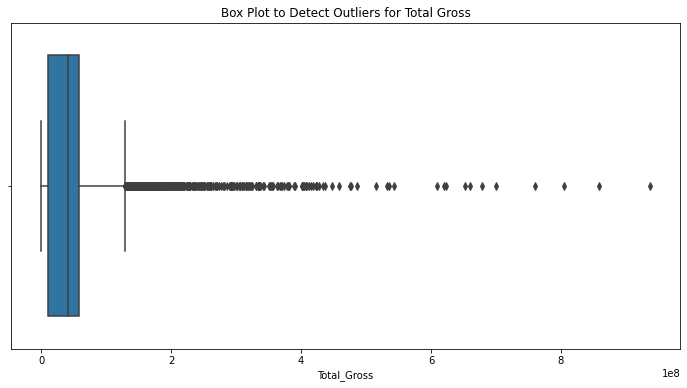

In [136]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='Total_Gross')
plt.title('Box Plot to Detect Outliers for Total Gross')
plt.show()

In [137]:
Q1 = df['Total_Gross'].quantile(0.25)
Q3 = df['Total_Gross'].quantile(0.75)
IQR = Q3 - Q1

In [138]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [139]:
df_cleaned = df[(df['Total_Gross'] >= lower_bound) & (df['Total_Gross'] <= upper_bound)]

In [140]:
print(f'Before cleaning: {df.shape[0]} rows')
print(f'After cleaning: {df_cleaned.shape[0]} rows')

Before cleaning: 5554 rows
After cleaning: 5073 rows


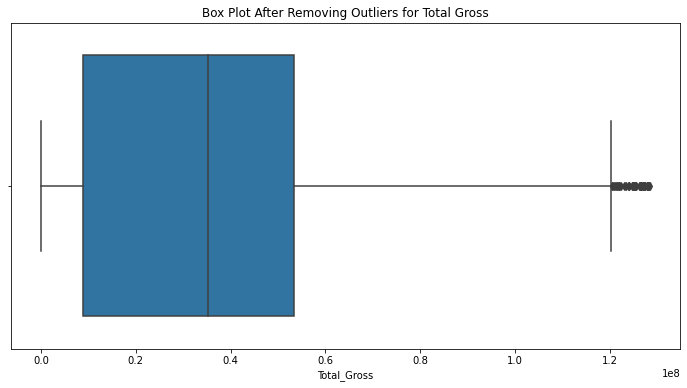

In [141]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_cleaned, x='Total_Gross')
plt.title('Box Plot After Removing Outliers for Total Gross')
plt.show()

#  Data Preprocessing

In [142]:
df.head(10)

,Movie_Title,Year,Director,Actors,Rating,Runtime(Mins),Censor,Total_Gross,main_genre,side_genre
0,Kantara,2022,Rishab Shetty,"Rishab Shetty, Sapthami Gowda, Kishore Kumar G...",9.3,148,UA,5.344339e+07,Action,"Adventure, Drama"
1,The Dark Knight,2008,Christopher Nolan,"Christian Bale, Heath Ledger, Aaron Eckhart, M...",9.0,152,UA,5.348600e+08,Action,"Crime, Drama"
2,The Lord of the Rings: The Return of the King,2003,Peter Jackson,"Elijah Wood, Viggo Mortensen, Ian McKellen, Or...",9.0,201,U,3.778500e+08,Action,"Adventure, Drama"
3,Inception,2010,Christopher Nolan,"Leonardo DiCaprio, Joseph Gordon-Levitt, Ellio...",8.8,148,UA,2.925800e+08,Action,"Adventure, Sci-Fi"
4,The Lord of the Rings: The Two Towers,2002,Peter Jackson,"Elijah Wood, Ian McKellen, Viggo Mortensen, Or...",8.8,179,UA,3.425500e+08,Action,"Adventure, Drama"
5,The Lord of the Rings: The Fellowship of the Ring,2001,Peter Jackson,"Elijah Wood, Ian McKellen, Orlando Bloom, Sean...",8.8,178,U,3.155400e+08,Action,"Adventure, Drama"
6,The Matrix,1999,"Directors:Lana Wachowski, Lilly Wachowski","Keanu Reeves, Laurence Fishburne, Carrie-Anne ...",8.7,136,A,1.714800e+08,Action,Sci-Fi
7,The Empire Strikes Back,1980,Irvin Kershner,"Mark Hamill, Harrison Ford, Carrie Fisher, Bil...",8.7,124,UA,2.904800e+08,Action,"Adventure, Fantasy"
8,Terminator 2: Judgment Day,1991,James Cameron,"Arnold Schwarzenegger, Linda Hamilton, Edward ...",8.6,137,A,2.048400e+08,Action,Sci-Fi
9,Star Wars,1977,George Lucas,"Mark Hamill, Harrison Ford, Carrie Fisher, Ale...",8.6,121,U,3.227400e+08,Action,"Adventure, Fantasy"


In [143]:
df_cleaned = df.drop(columns=['Actors', 'Director', 'side_genre', 'Movie_Title'])
df_cleaned.head()

,Year,Rating,Runtime(Mins),Censor,Total_Gross,main_genre
0,2022,9.3,148,UA,5.344339e+07,Action
1,2008,9.0,152,UA,5.348600e+08,Action
2,2003,9.0,201,U,3.778500e+08,Action
3,2010,8.8,148,UA,2.925800e+08,Action
4,2002,8.8,179,UA,3.425500e+08,Action


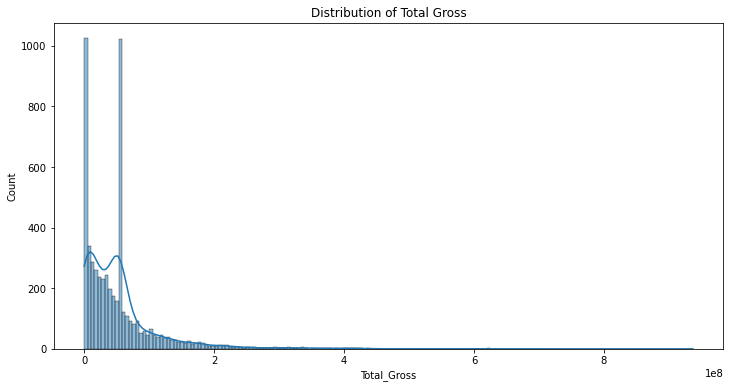

In [144]:
plt.figure(figsize=(12, 6))
sns.histplot(df_cleaned['Total_Gross'], kde=True)
plt.title('Distribution of Total Gross')
plt.show()


In [145]:
df_cleaned['Censor'] = df_cleaned['Censor'].astype('category')
df_cleaned['main_genre'] = df_cleaned['main_genre'].astype('category')

# Feature Engineering

In [146]:
df_cleaned['Total_Gross_x_Rating'] = df_cleaned['Total_Gross'] * df_cleaned['Rating']
df_cleaned['Runtime_x_main_genre'] = df_cleaned['Runtime(Mins)'] * df_cleaned['main_genre'].cat.codes

In [147]:
df_cleaned['Years_since_release'] = 2024 - df_cleaned['Year']

In [148]:
df_cleaned['Revenue_per_minute'] = df_cleaned['Total_Gross'] / df_cleaned['Runtime(Mins)']

In [149]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
df_cleaned['Censor'] = label_encoder.fit_transform(df_cleaned['Censor'])

In [150]:
df_cleaned = pd.get_dummies(df_cleaned, columns=['main_genre'], drop_first=True)
df_cleaned.head()

,Year,Rating,Runtime(Mins),Censor,Total_Gross,Total_Gross_x_Rating,Runtime_x_main_genre,Years_since_release,Revenue_per_minute,main_genre_Adventure,...,main_genre_Biography,main_genre_Comedy,main_genre_Crime,main_genre_Drama,main_genre_Fantasy,main_genre_Film-Noir,main_genre_Horror,main_genre_Musical,main_genre_Mystery,main_genre_Western
0,2022,9.3,148,20,5.344339e+07,4.970236e+08,0,2,3.611040e+05,0,...,0,0,0,0,0,0,0,0,0,0
1,2008,9.0,152,20,5.348600e+08,4.813740e+09,0,16,3.518816e+06,0,...,0,0,0,0,0,0,0,0,0,0
2,2003,9.0,201,18,3.778500e+08,3.400650e+09,0,21,1.879851e+06,0,...,0,0,0,0,0,0,0,0,0,0
3,2010,8.8,148,20,2.925800e+08,2.574704e+09,0,14,1.976892e+06,0,...,0,0,0,0,0,0,0,0,0,0
4,2002,8.8,179,20,3.425500e+08,3.014440e+09,0,22,1.913687e+06,0,...,0,0,0,0,0,0,0,0,0,0


# Correlation Matrix

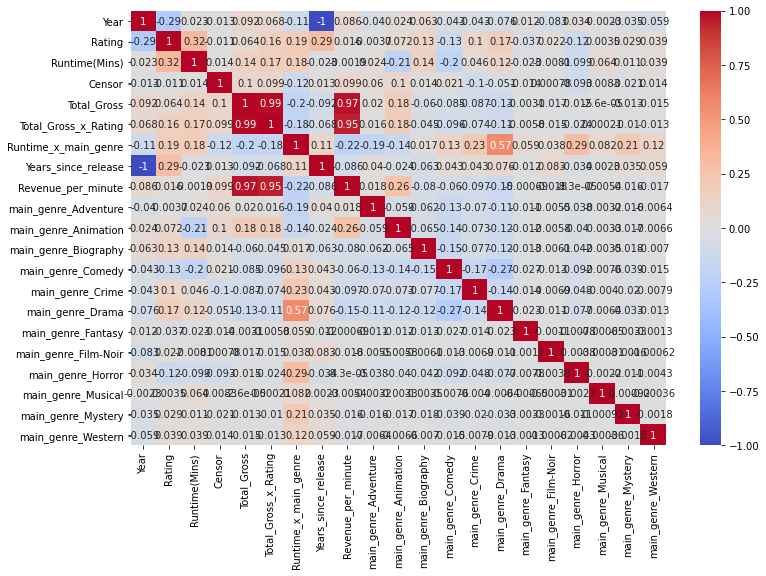

In [151]:
correlation_matrix = df_cleaned.corr()
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.show()

# Discover Features

In [152]:
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
X = df_cleaned.drop(['Total_Gross'], axis=1)
y = df_cleaned['Total_Gross']
selector = SelectKBest(score_func=f_regression, k=5)
X_new = selector.fit_transform(X, y)
selected_features = X.columns[selector.get_support()]
print("Top 5 Features: ", selected_features)

Top 5 Features:  Index(['Runtime(Mins)', 'Total_Gross_x_Rating', 'Runtime_x_main_genre',
       'Revenue_per_minute', 'main_genre_Animation'],
      dtype='object')


In [153]:
from sklearn.ensemble import RandomForestRegressor

In [154]:
model = RandomForestRegressor(random_state=42)
model.fit(X, y)

RandomForestRegressor(random_state=42)

In [155]:
feature_importances = model.feature_importances_

In [156]:
important_features = X.columns[feature_importances > 0.05]
print("Top Features: ", important_features)

Top Features:  Index(['Total_Gross_x_Rating'], dtype='object')


In [157]:
from sklearn.decomposition import PCA

In [158]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

In [159]:
df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
print(df_pca.head())

            PC1           PC2
0  1.309042e+08  2.568713e+05
1  4.447622e+09  1.728839e+06
2  3.034531e+09  1.852264e+06
3  2.208585e+09  8.693964e+05
4  2.648321e+09  1.404218e+06


In [160]:
from sklearn.manifold import TSNE

In [161]:
tsne = TSNE(n_components=2)
X_tsne = tsne.fit_transform(X)

In [162]:
df_tsne = pd.DataFrame(X_tsne, columns=['TSNE1', 'TSNE2'])
df_tsne.head()

,TSNE1,TSNE2
0,35.603157,-46.686779
1,88.367088,18.247404
2,88.900688,16.254498
3,89.727585,10.890846
4,89.205315,14.577328


# Scaling 

In [163]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split

In [164]:
X = df_cleaned[['Runtime(Mins)', 'Total_Gross_x_Rating', 'Runtime_x_main_genre', 'Revenue_per_minute', 'main_genre_Animation']]
y = df_cleaned['Total_Gross']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [165]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), ['Runtime(Mins)', 'Total_Gross_x_Rating', 'Runtime_x_main_genre', 'Revenue_per_minute'])
    ],
    remainder='passthrough'
)

X_transformed = preprocessor.fit_transform(X)

# Data Modelling

In [166]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

In [167]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

LinearRegression()

In [168]:
y_pred_lr = lr_model.predict(X_test)

In [223]:
mae_lr = mean_absolute_error(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = mean_squared_error(y_test, y_pred_lr, squared=False)
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression - MAE:", mae_lr)
print("Linear Regression - MSE:", mse_lr)
print("Linear Regression - RMSE:", rmse_lr)
print("Linear Regression - R² Score:", r2_lr)

Linear Regression - MAE: 3412358.4478445053
Linear Regression - MSE: 38756075776360.93
Linear Regression - RMSE: 6225437.797967379
Linear Regression - R² Score: 0.9885437122525713


In [170]:
from sklearn.ensemble import RandomForestRegressor

In [171]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

In [172]:
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

In [173]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = mean_squared_error(y_test, y_pred_rf, squared=False)  
r2_rf = r2_score(y_test, y_pred_rf)

print("\nRandom Forest Regressor:")
print("MAE:", mae_rf)
print("MSE:", mse_rf)
print("RMSE:", rmse_rf)
print("R² Score:", r2_rf)


Random Forest Regressor:
MAE: 1686211.5230121217
MSE: 29490952493608.016
RMSE: 5430557.291255476
R² Score: 0.9912824807221943


In [174]:
from sklearn.model_selection import cross_val_score
scores_rf = cross_val_score(rf_model, X_train, y_train, cv=5, scoring='r2')
print("Cross Validation R² Scores:", scores_rf)
print("Mean Cross Validation R² Score:", scores_rf.mean())

Cross Validation R² Scores: [0.99305928 0.99165325 0.98956578 0.99336386 0.98886796]
Mean Cross Validation R² Score: 0.99130202614731


In [175]:
from sklearn.tree import DecisionTreeRegressor

In [176]:
dt_model = DecisionTreeRegressor(random_state=42)

In [177]:
dt_model.fit(X_train, y_train)

DecisionTreeRegressor(random_state=42)

In [178]:
y_pred_dt = dt_model.predict(X_test)

In [225]:
mae_dt = mean_absolute_error(y_test, y_pred_dt)
mse_dt = mean_squared_error(y_test, y_pred_dt)
rmse_dt = mean_squared_error(y_test, y_pred_dt, squared=False)
r2_dt = r2_score(y_test, y_pred_dt)

In [180]:
scores_dt = cross_val_score(dt_model, X_transformed, y, cv=5, scoring='r2')

In [226]:
print("MAE:", mae_dt)
print("MSE:", mse_dt)
print("RMSE:", rmse_dt)
print("R² Score:", r2_dt)
print("Cross Validation R² scores:", scores_dt)
print("Mean Cross Validation R² score:", scores_dt.mean())

MAE: 2106078.8251812067
MSE: 35511593507796.65
RMSE: 5959160.47004917
R² Score: 0.9895027805203337
Cross Validation R² scores: [0.94669898 0.97137457 0.99135213 0.98715545 0.97989348]
Mean Cross Validation R² score: 0.9752949227651435


In [182]:
from sklearn.model_selection import GridSearchCV

In [183]:
param_grid_dt = {
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5]
}

In [184]:
grid_search_dt = GridSearchCV(dt_model, param_grid_dt, cv=5, scoring='r2')
grid_search_dt.fit(X_transformed, y)

GridSearchCV(cv=5, estimator=DecisionTreeRegressor(random_state=42),
             param_grid={'max_depth': [3, 5, 10, None],
                         'min_samples_leaf': [1, 2, 5],
                         'min_samples_split': [2, 5, 10]},
             scoring='r2')

In [185]:
print("Best Parameters for Decision Tree:", grid_search_dt.best_params_)
print("Best Score:", grid_search_dt.best_score_)

Best Parameters for Decision Tree: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 5}
Best Score: 0.9777983291668664


In [186]:
from sklearn.svm import SVR

In [187]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [188]:
svr_model = SVR(kernel='rbf')

In [189]:
svr_model.fit(X_train_scaled, y_train)

SVR()

In [190]:
y_pred_svr = svr_model.predict(X_test_scaled)

In [228]:
mae_svr = mean_absolute_error(y_test, y_pred_svr)
mse_svr = mean_squared_error(y_test, y_pred_svr)
rmse_svr = mean_squared_error(y_test, y_pred_svr, squared=False)
r2_svr = r2_score(y_test, y_pred_svr)

In [229]:
print("\nSupport Vector Regressor:")
print("MAE:", mae_svr)
print("MSE:", mse_svr)
print("RMSE:", rmse_svr)
print("R² Score:", r2_svr)


Support Vector Regressor:
MAE: 36283241.43270428
MSE: 3447218331846698.5
RMSE: 58713016.71560318
R² Score: -0.01899700490149181


In [193]:
from sklearn.preprocessing import StandardScaler
from sklearn import metrics

def calculate_scaled_metrics(y_test, predictions):

    y_test_reshaped = y_test.to_numpy().reshape(-1, 1)
    predictions_reshaped = predictions.reshape(-1, 1)

    scaler = StandardScaler()
    scaled_Target = scaler.fit_transform(y_test_reshaped)
    pre_scaled_values = scaler.transform(predictions_reshaped)

    mae = metrics.mean_absolute_error(scaled_Target, pre_scaled_values)
    mse = metrics.mean_squared_error(scaled_Target, pre_scaled_values)
    rmse = np.sqrt(mse)

    print('MAE (Scaled):', mae)
    print('MSE (Scaled):', mse)
    print('RMSE (Scaled):', rmse)

print("\nLinear Regression:")
calculate_scaled_metrics(y_test, y_pred_lr)

print("\nRandom Forest Regressor:")
calculate_scaled_metrics(y_test, y_pred_rf)

print("\nDecision Tree Regressor:")
calculate_scaled_metrics(y_test, y_pred_dt)

print("\nSupport Vector Regressor:")
calculate_scaled_metrics(y_test, y_pred_svr)



Linear Regression:
MAE (Scaled): 0.05866873219082543
MSE (Scaled): 0.011456287747428727
RMSE (Scaled): 0.10703404947692452

Random Forest Regressor:
MAE (Scaled): 0.02899106110120762
MSE (Scaled): 0.008717519277805681
RMSE (Scaled): 0.09336765648663183

Decision Tree Regressor:
MAE (Scaled): 0.0362098461975396
MSE (Scaled): 0.010497219479666333
RMSE (Scaled): 0.10245593921128406

Support Vector Regressor:
MAE (Scaled): 0.62381833771743
MSE (Scaled): 1.0189970049014916
RMSE (Scaled): 1.0094538151403913


In [194]:
from scipy.stats import boxcox
y_train_transformed, lambda_ = boxcox(y_train + 1)


In [195]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, median_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVR

In [196]:
parameters = {
    'kernel': ['rbf', 'linear', 'poly'],
    'C': [0.1, 1, 10, 100, 1000],
    'gamma': [0.001, 0.01, 0.1, 1, 'scale', 'auto'],
    'degree': [2, 3, 4]
}

In [197]:
svr = SVR()

In [198]:
grid_search = GridSearchCV(svr, parameters, scoring='neg_mean_absolute_error', cv=5)
grid_search.fit(X_train_scaled, y_train)

GridSearchCV(cv=5, estimator=SVR(),
             param_grid={'C': [0.1, 1, 10, 100, 1000], 'degree': [2, 3, 4],
                         'gamma': [0.001, 0.01, 0.1, 1, 'scale', 'auto'],
                         'kernel': ['rbf', 'linear', 'poly']},
             scoring='neg_mean_absolute_error')

In [199]:
best_svr = grid_search.best_estimator_
print("best param:", grid_search.best_params_)


best param: {'C': 1000, 'degree': 3, 'gamma': 1, 'kernel': 'poly'}


In [200]:
y_pred = best_svr.predict(X_test_scaled)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred, squared=False)
med_ae = median_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

In [201]:
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("Median AE:", med_ae)
print("R² Score:", r2)

MAE: 23705327.543176632
MSE: 1093823715608619.1
RMSE: 33073005.844776478
Median AE: 17690167.723486647
R² Score: 0.6766659425664219


In [202]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [203]:
from sklearn.feature_selection import SelectKBest, f_regression

selector = SelectKBest(score_func=f_regression, k=5)
X_train_reduced = selector.fit_transform(X_train_scaled, y_train)
X_test_reduced = selector.transform(X_test_scaled)


In [204]:
svr_linear = SVR(kernel='linear', C=10)
svr_linear.fit(X_train_scaled, y_train)
y_pred_linear = svr_linear.predict(X_test_scaled)


In [205]:
svm_model_scaled = grid_search.best_estimator_

y_pred_svm_scaled = svm_model_scaled.predict(X_test_scaled)
mae_svm_scaled = mean_absolute_error(y_test, y_pred_svm_scaled)
mse_svm_scaled = mean_squared_error(y_test, y_pred_svm_scaled)
r2_svm_scaled = r2_score(y_test, y_pred_svm_scaled)

print("\nSVM with Scaling - MAE:", mae_svm_scaled)
print("SVM with Scaling - MSE:", mse_svm_scaled)
print("SVM with Scaling - R² Score:", r2_svm_scaled)


SVM with Scaling - MAE: 23705327.543176632
SVM with Scaling - MSE: 1093823715608619.1
SVM with Scaling - R² Score: 0.6766659425664219


In [206]:
from sklearn.decomposition import PCA

pca = PCA(n_components=5)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)


In [207]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred_best = best_svr.predict(X_test_scaled)
print("MAE:", mean_absolute_error(y_test, y_pred_best))
print("MSE:", mean_squared_error(y_test, y_pred_best))
print("RMSE:", mean_squared_error(y_test, y_pred_best, squared=False))
print("R² Score:", r2_score(y_test, y_pred_best))


MAE: 23705327.543176632
MSE: 1093823715608619.1
RMSE: 33073005.844776478
R² Score: 0.6766659425664219


In [208]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_train_normalized = scaler.fit_transform(X_train)
X_test_normalized = scaler.transform(X_test)

In [209]:
svr_model = SVR(kernel='rbf', C=1, gamma='scale')
svr_model.fit(X_train_normalized, y_train)
y_pred = svr_model.predict(X_test_normalized)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("R² Score:", r2_score(y_test, y_pred))

MAE: 36283348.57529746
MSE: 3447224795557435.0
R² Score: -0.018998915573009256


In [210]:
from sklearn.decomposition import PCA


In [211]:
pca = PCA(n_components=5)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

In [212]:
svm_model_pca = SVR()
svm_model_pca.fit(X_train_pca, y_train)

SVR()

In [213]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
y_pred_best = best_svr.predict(X_test_scaled)
print("MAE:", mean_absolute_error(y_test, y_pred_best))
print("MSE:", mean_squared_error(y_test, y_pred_best))
print("RMSE:", mean_squared_error(y_test, y_pred_best, squared=False))
print("R² Score:", r2_score(y_test, y_pred_best))

MAE: 23705327.543176632
MSE: 1093823715608619.1
RMSE: 33073005.844776478
R² Score: 0.6766659425664219


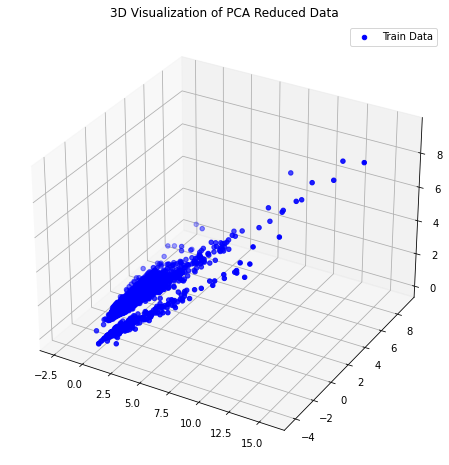

In [214]:
from mpl_toolkits.mplot3d import Axes3D

plt.figure(figsize=(8, 8))
ax = plt.axes(projection='3d')
ax.scatter(X_train_pca[:, 0], X_train_pca[:, 1], y_train, c='blue', label='Train Data')
ax.set_title('3D Visualization of PCA Reduced Data')
plt.legend()
plt.show()


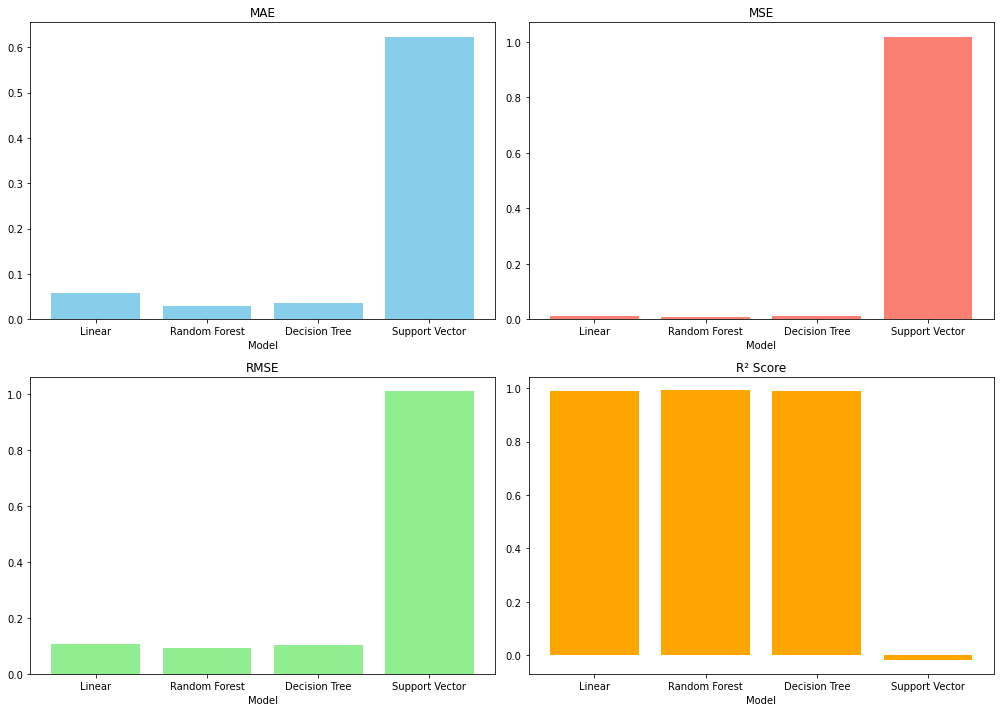

In [244]:
def calculate_scaled_metrics(y_test, predictions):
    y_test_reshaped = y_test.to_numpy().reshape(-1, 1)
    predictions_reshaped = predictions.reshape(-1, 1)

    scaler = StandardScaler()
    scaled_Target = scaler.fit_transform(y_test_reshaped)
    pre_scaled_values = scaler.transform(predictions_reshaped)

    mae = metrics.mean_absolute_error(scaled_Target, pre_scaled_values)
    mse = metrics.mean_squared_error(scaled_Target, pre_scaled_values)
    rmse = np.sqrt(mse)

    return mae, mse, rmse

metrics_data = {
    "Model": ["Linear", "Random Forest", "Decision Tree", "Support Vector"],
    "MAE": [
        calculate_scaled_metrics(y_test, y_pred_lr)[0],
        calculate_scaled_metrics(y_test, y_pred_rf)[0],
        calculate_scaled_metrics(y_test, y_pred_dt)[0],
        calculate_scaled_metrics(y_test, y_pred_svr)[0]
    ],
    "MSE": [
        calculate_scaled_metrics(y_test, y_pred_lr)[1],
        calculate_scaled_metrics(y_test, y_pred_rf)[1],
        calculate_scaled_metrics(y_test, y_pred_dt)[1],
        calculate_scaled_metrics(y_test, y_pred_svr)[1],
    ],
    "RMSE": [
        calculate_scaled_metrics(y_test, y_pred_lr)[2],
        calculate_scaled_metrics(y_test, y_pred_rf)[2],
        calculate_scaled_metrics(y_test, y_pred_dt)[2],
        calculate_scaled_metrics(y_test, y_pred_svr)[2],
    ],
}

df_metrics = pd.DataFrame(metrics_data)
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

ax[0, 0].bar(df_metrics["Model"], df_metrics["MAE"], color='skyblue')
ax[0, 0].set_title("MAE")
ax[0, 0].set_xlabel("Model")

ax[0, 1].bar(df_metrics["Model"], df_metrics["MSE"], color='salmon')
ax[0, 1].set_title("MSE")
ax[0, 1].set_xlabel("Model")

ax[1, 0].bar(df_metrics["Model"], df_metrics["RMSE"], color='lightgreen')
ax[1, 0].set_title("RMSE")
ax[1, 0].set_xlabel("Model")

r2_scores = [
    r2_score(y_test, y_pred_lr),
    r2_score(y_test, y_pred_rf),
    r2_score(y_test, y_pred_dt),
    r2_score(y_test, y_pred_svr)
]
ax[1, 1].bar(df_metrics["Model"], r2_scores, color='orange')
ax[1, 1].set_title("R² Score")
ax[1, 1].set_xlabel("Model")

plt.subplots_adjust(hspace=0.3, wspace=0.3) 
plt.tight_layout()
plt.show()


# Check if normalization affects accuracy

In [261]:
lr_model_no_norm = LinearRegression()
lr_model_no_norm.fit(X_train, y_train)
y_pred_no_norm = lr_model_no_norm.predict(X_test)
r2_no_norm = r2_score(y_test, y_pred_no_norm)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_model_norm = LinearRegression()
lr_model_norm.fit(X_train_scaled, y_train)
y_pred_norm = lr_model_norm.predict(X_test_scaled)
r2_norm = r2_score(y_test, y_pred_norm)

print("R² without normalization:", r2_no_norm)
print("R² with normalization:", r2_norm)


R² without normalization: 0.9885437122525713
R² with normalization: 0.988543712252572


# Check if dimensionality reduction affects accuracy

In [262]:
lr_model_no_pca = LinearRegression()
lr_model_no_pca.fit(X_train, y_train)
y_pred_no_pca = lr_model_no_pca.predict(X_test)
r2_no_pca = r2_score(y_test, y_pred_no_pca)

pca = PCA(n_components=0.95)  
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

lr_model_pca = LinearRegression()
lr_model_pca.fit(X_train_pca, y_train)
y_pred_pca = lr_model_pca.predict(X_test_pca)
r2_pca = r2_score(y_test, y_pred_pca)

print("R² without dimensionality reduction:", r2_no_pca)
print("R² with dimensionality reduction (PCA):", r2_pca)

R² without dimensionality reduction: 0.9885437122525713
R² with dimensionality reduction (PCA): 0.972267549555148


In [245]:
columns_to_drop = ['Censor'] + [col for col in df.columns if col.startswith('main_genre_')]
features = df.drop(columns=columns_to_drop, errors='ignore')

In [246]:
from sklearn.preprocessing import StandardScaler, LabelEncoder

features_processed = features.copy()

columns_to_drop = ['Movie_Title', 'Director', 'Actors']
features_processed = features_processed.drop(columns=columns_to_drop, axis=1)
label_encoders = {}
for col in ['main_genre', 'side_genre']:
    le = LabelEncoder()
    features_processed[col] = le.fit_transform(features_processed[col])
    label_encoders[col] = le
print(features_processed.dtypes)
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features_processed)


Year               int64
Rating           float64
Runtime(Mins)      int64
Total_Gross      float64
main_genre         int32
side_genre         int32
dtype: object


In [247]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
numeric_columns = features.select_dtypes(include=['number'])

In [248]:
scaler = StandardScaler()
scaled_features = scaler.fit_transform(numeric_columns)
import pandas as pd
scaled_features_df = pd.DataFrame(scaled_features, columns=numeric_columns.columns)

scaled_features_df.head()

,Year,Rating,Runtime(Mins),Total_Gross
0,1.190264,2.713807,1.654113,-0.001959
1,0.323365,2.393785,1.839113,6.999687
2,0.013758,2.393785,4.105369,4.716159
3,0.447208,2.180438,1.654113,3.476005
4,-0.048164,2.180438,3.087867,4.202761


In [249]:
from sklearn.cluster import KMeans

n_classes = 3
kmeans = KMeans(n_clusters=n_classes, random_state=42)
clusters = kmeans.fit_predict(scaled_features)


C:\Users\Right-click\anaconda3\anaconda\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning:

The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning



In [250]:
pca = PCA(n_components=2)
reduced_features = pca.fit_transform(scaled_features)

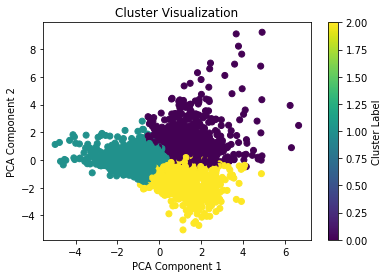

In [251]:
plt.scatter(reduced_features[:, 0], reduced_features[:, 1], c=clusters, cmap='viridis')
plt.title('Cluster Visualization')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.colorbar(label='Cluster Label')
plt.show()

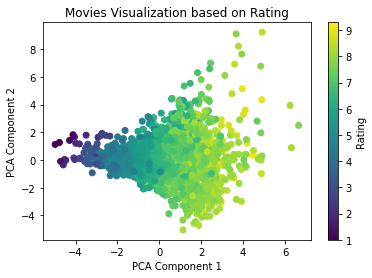

In [252]:
plt.scatter(reduced_features[:, 0], reduced_features[:, 1], c=df['Rating'], cmap='viridis')
plt.title('Movies Visualization based on Rating')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.colorbar(label='Rating')
plt.show()

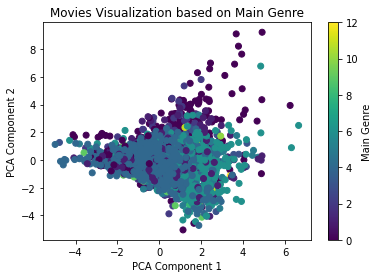

In [253]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()

df['main_genre_encoded'] = label_encoder.fit_transform(df['main_genre'])

plt.scatter(reduced_features[:, 0], reduced_features[:, 1], c=df['main_genre_encoded'], cmap='viridis')
plt.title('Movies Visualization based on Main Genre')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.colorbar(label='Main Genre')
plt.show()

In [254]:
from sklearn.metrics import adjusted_rand_score
ari = adjusted_rand_score(df['main_genre_encoded'], clusters)
print("Adjusted Rand Index:", ari)

Adjusted Rand Index: 0.02451509086790686


In [255]:
from sklearn.metrics import silhouette_score
silhouette = silhouette_score(scaled_features, clusters)
print("Silhouette Score:", silhouette)


Silhouette Score: 0.28743255464411194


### I hope you like it